# Município contracts

Contracts whose **adjudicante** name starts with "Município".

**Rule:** after splitting the packed `NIPC - name` field, the name is accent-folded and lowercased
(`normalize_name()`), then matched with `startswith("municipio")`. A naive `starts_with("Município")`
would lose ~3 % of rows (unaccented / uppercase variants such as `MUNICÍPIO DA FIGUEIRA DA FOZ`).

Reference values on the current parquet: **93 516 rows, 309 distinct NIPC** (checked against the data).

Caveats: 309 NIPCs vs 308 real municipalities → at least one false positive
(e.g. `Município de Formação AIRC`). `Câmara Municipal …` names do **not** start with "Município"
and are deliberately excluded (see the near-miss cell).

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl

from base_gov.contracts import is_municipio_expr, load_contracts
from base_gov.entities import (
    canonical_names,
    normalize_name,
)
from base_gov.stats import MIN_VALUE, value_impact

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_all = load_contracts(DATA / "contracts.parquet")
print(f"rows={contracts_all.height:,}  cols={contracts_all.width}")
# Disregard contracts flagged is_below_min_value (|preco_contratual| < MIN_VALUE, €); contracts_all keeps them for before/after comparisons.
contracts = contracts_all.filter(~pl.col("is_below_min_value"))
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with |preco_contratual| < €{MIN_VALUE:g} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()

rows=643,548  cols=31
disregarded 2,307 contracts with |preco_contratual| < €10 (0.36%); kept 641,241
valor_por_dia defined for 99.0% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)


idcontrato,ano,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,desc_contrato,preco_contratual,preco_total_efetivo,preco_base_procedimento,prazo_execucao,valor_por_dia,data_celebracao,data_publicacao,data_fecho,tipo_contrato,tipo_procedimento,fundament_ajuste_direto,cpv,nuts,concorrentes,TipoCriterioAdjudicacao,n_concorrentes,is_municipio,is_below_min_value,row_hash,first_ingested_at,updated_at
i64,i32,str,str,str,str,str,str,str,str,f64,f64,f64,i64,f64,date,date,date,str,str,str,str,str,str,str,u32,bool,bool,i64,"datetime[μs, UTC]","datetime[μs, UTC]"
11051950,2024,"""501413197 - Universidade do Po…","""501413197""","""Universidade do Porto - Faculd…","""501413197""","""nipc""","""500126623 - Gertal - Companhia…","""Aquisição de refeições confeci…","""Aquisição de refeições confeci…",3.8767e6,0.0,4.5642e6,364,10650.394368,2024-11-12,2024-11-27,null,"""Aquisição de bens móveis""","""Concurso público""",null,"""15894200-3 - Refeições prepara…","""PT11A - Área Metropolitana do …","""501323325-Uniself - Sociedade …","""Monofator""",4,false,false,-3226272757099977435,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11060512,2024,"""501442600 - Instituto do Empre…","""501442600""","""Instituto do Emprego e da Form…","""501442600""","""nipc""","""- - Pedro Emanuel Ribeiro da R…","""Serviços de Formação Profissio…","""AQUISIÇÃO SERVIÇOS DE FORMAÇÃO…",5000.0,5000.0,5000.0,365,13.69863,2024-09-03,2024-12-03,2025-05-23,"""Aquisição de serviços""","""Contratação excluída II""",null,"""80530000-8 - Serviços de forma…",null,"""--Pedro Emanuel Ribeiro da Roc…","""Monofator""",1,false,false,-2579447276048904472,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11064174,2024,"""506803228 - ATEC - Associação …","""506803228""","""ATEC - Associação de Formação …","""506803228""","""nipc""","""516273302 - AM-Ferramentas de …","""Aquisição de material para Mec…","""Aquisição de material para Mec…",94388.61,0.0,108500.0,730,129.299466,2024-12-04,2024-12-04,null,"""Aquisição de bens móveis""","""Concurso público""",null,"""34300000-0 - Peças e acessório…","""PTZZZ - Extra-Regio NUTS 3 (To…","""510953859-PBTOOLS - unipessoal…","""Multifator""",7,false,false,-4867324996322863534,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11089864,2024,"""506362299 - Instituto Portuguê…","""506362299""","""Instituto Português de Oncolog…","""506362299""","""nipc""","""500039720 - AVIQUÍMICA - IMPOR…","""TOALHETE DESINFETANTE PARA SUP…","""41411524 - TOALHETE DESINFETAN…",191.52,0.0,191.52,20,9.576,2024-10-17,2024-12-16,null,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""33000000-0 - Equipamento médic…","""PT11A - Área Metropolitana do …",null,"""Monofator""",null,false,false,6174870913128464768,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC
11045330,2024,"""501510184 - ISCTE - Instituto …","""501510184""","""ISCTE - Instituto Universitári…","""501510184""","""nipc""","""501364668 - Seleprinter - Soci…","""AQUISIÇÃO DE FOLHETOS PARA O I…","""AQUISIÇÃO DE FOLHETOS PARA O I…",200.0,200.0,200.0,60,3.333333,2024-10-30,2024-11-25,2024-12-06,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,"""22140000-3 - Folhetos""",null,null,"""Monofator""",null,false,false,-1631265789765637343,2026-09-01 00:00:00 UTC,2026-09-01 00:00:00 UTC


In [3]:
municipio = contracts.filter(is_municipio_expr())
n_entities = municipio["adjudicante_key"].n_unique()
print(f"Município rows: {municipio.height:,}  distinct keys: {n_entities}  "
      f"share of all contracts: {municipio.height / contracts.height:.1%}")
assert 0 < municipio.height < contracts.height

Município rows: 150,103  distinct keys: 313  share of all contracts: 23.4%


In [4]:
# Effect of disregarding contracts with |value| below €10 on Município contracts.
before = contracts_all.filter(is_municipio_expr())
display(value_impact(before, municipio))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",150391.0,150103.0,-288.0,-0.19
"""mean_value""",89951.341098,90123.928485,172.587387,0.19
"""median_value""",18450.0,18500.0,50.0,0.27
"""total_value""",1.3528e10,1.3528e10,-101.700001,-0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 1,752 of 150,103


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
5.0,30.0,120.0,365.0,730.0,26.71,54.1,231.6,958.39,3396.73


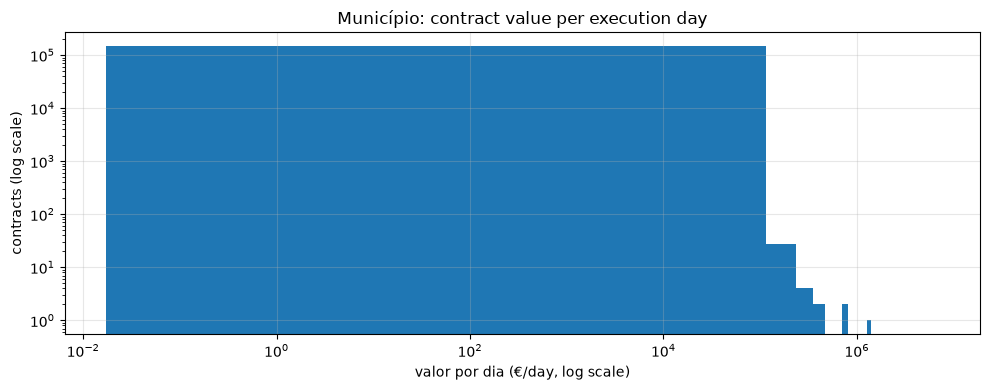

In [5]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = municipio
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Município: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    municipio.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",45114,12000.0,1121.29,1.0155e9
"""91-365 d""",56024,19200.0,72.62,5.0399e9
"""31-90 d""",23988,20705.77,378.92,1.1498e9
"""366-3650 d""",23225,35238.0,44.94,5.9196e9


In [7]:
print("adjudicante cells with several entries ('\\n'):", municipio.filter(pl.col("adjudicante").str.contains("\n", literal=True)).height,
      "(whole dataset:", contracts.filter(pl.col("adjudicante").str.contains("\n", literal=True)).height, ")")
print("non-9-digit NIPC:", municipio.filter(pl.col("adjudicante_key_source") != "nipc").height)
print("null preco_contratual:", municipio["preco_contratual"].null_count())
print("null data_celebracao:", municipio["data_celebracao"].null_count())
print("no-NIF ('-') adjudicante rows, whole dataset:", contracts.filter(pl.col("adjudicante_key_source") == "name").height)
print(contracts["adjudicante_key_source"].value_counts(sort=True))


adjudicante cells with several entries ('\n'): 4 (whole dataset: 42 )
non-9-digit NIPC: 18
null preco_contratual: 0
null data_celebracao: 63
no-NIF ('-') adjudicante rows, whole dataset: 252
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 640989 │
│ name                   ┆ 252    │
└────────────────────────┴────────┘


In [8]:
# Names containing "munic" that the rule does NOT match (justifies the prefix rule).
near_miss = (
    contracts
    .with_columns(pl.col("adjudicante_name").map_elements(normalize_name, return_dtype=pl.String).alias("norm_name"))
    .filter(pl.col("norm_name").str.contains("munic") & ~pl.col("norm_name").str.starts_with("municipio"))
    .group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"))
    .join(canonical_names(contracts, prefix="adjudicante"), on="adjudicante_key", how="left")
    .sort("n_contracts", descending=True)
)
print(f"excluded near-miss rows: {near_miss['n_contracts'].sum():,}")
near_miss.head(15)


excluded near-miss rows: 22,437


adjudicante_key,n_contracts,adjudicante_name
str,u32,str
"""505037700""",1492,"""CMPH - DomusSocial - Empresa d…"
"""502017368""",948,"""Autoridade Nacional de Comunic…"
"""503541567""",694,"""Gebalis - Gestão do Arrendamen…"
"""501091823""",618,"""Câmara Municipal de Felgueiras"""
"""680009671""",544,"""Serviços Intermunicipalizados …"
"""501305912""",514,"""Município de Matosinhos"""
"""507718666""",503,"""CMPEAE - Empresa de Águas e En…"
"""680000054""",496,"""Serviços Municipalizados de Ág…"
"""507396081""",494,"""EMAC - Empresa Municipal de Am…"


In [9]:
by_entity = (
    municipio
    .group_by("adjudicante_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
    )
    .join(canonical_names(municipio, prefix="adjudicante"), on="adjudicante_key", how="left")
)
assert by_entity["n_contracts"].sum() == municipio.height

print("Top 20 municipalities by contract count:")
display(by_entity.sort("n_contracts", descending=True).head(20))
print("\nTop 20 municipalities by total contracted value:")
display(by_entity.sort("total_value", descending=True).head(20))


Top 20 municipalities by contract count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""500051070""",2973,4.3111e8,"""Município de Lisboa"""
"""500051062""",2410,3.1692e8,"""Município de Sintra"""
"""500745943""",2263,3.6513e8,"""Município de Oeiras"""
"""506663264""",1788,1.9403e8,"""Município de Vila Nova de Fama…"
"""501306099""",1686,1.9313e8,"""Município do Porto"""
"""502098139""",1672,1.7006e8,"""Município de Loulé"""
"""505804786""",1612,1.1390e8,"""Município de Vila do Conde"""
"""506901173""",1493,1.7451e8,"""Município de Braga"""
"""501138960""",1468,7.1620e7,"""Município de Valongo"""



Top 20 municipalities by total contracted value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""505187531""",1346,5.5651e8,"""Município de Cascais"""
"""500051070""",2973,4.3111e8,"""Município de Lisboa"""
"""500745943""",2263,3.6513e8,"""Município de Oeiras"""
"""500051062""",2410,3.1692e8,"""Município de Sintra"""
"""501294996""",1334,2.2816e8,"""Município de Loures"""
"""506663264""",1788,1.9403e8,"""Município de Vila Nova de Fama…"
"""501306099""",1686,1.9313e8,"""Município do Porto"""
"""501305912""",1198,1.9278e8,"""Município de Matosinhos"""
"""504293125""",1213,1.7564e8,"""Município de Odivelas"""


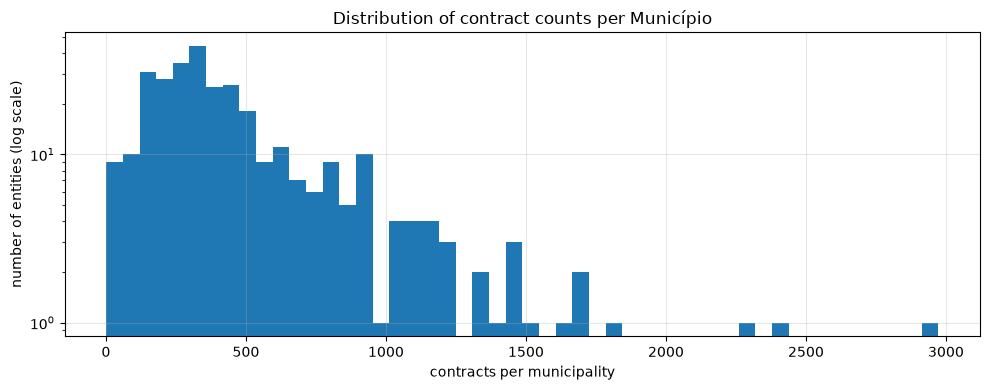

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 313.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 479.5623   │
│ std        ┆ 391.789955 │
│ min        ┆ 1.0        │
│ 25%        ┆ 239.0      │
│ 50%        ┆ 354.0      │
│ 75%        ┆ 572.0      │
│ max        ┆ 2973.0     │
└────────────┴────────────┘


In [10]:
fig, ax = plt.subplots()
ax.hist(by_entity["n_contracts"].to_numpy(), bins=50, log=True)
ax.set_xlabel("contracts per municipality")
ax.set_ylabel("number of entities (log scale)")
ax.set_title("Distribution of contract counts per Município")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(by_entity["n_contracts"].describe())


In [11]:
total_value = municipio["preco_contratual"].sum()
print(f"total value: €{total_value / 1e6:,.1f}M  median contract: €{municipio['preco_contratual'].median():,.0f}")
(
    municipio.group_by("tipo_procedimento")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum() * 100).round(1).alias("pct_count"),
        (pl.col("total_value") / pl.col("total_value").sum() * 100).round(1).alias("pct_value"),
    )
    .sort("n_contracts", descending=True)
)


total value: €13,527.9M  median contract: €18,500


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",73529,1.5686e9,49.0,11.6
"""Consulta Prévia""",43128,1.5855e9,28.7,11.7
"""Concurso público""",27131,8.6636e9,18.1,64.0
"""Contratação excluída II""",2357,2.8761e8,1.6,2.1
"""Ao abrigo de acordo-quadro (ar…",1724,4.6157e8,1.1,3.4
"""Ao abrigo de acordo-quadro (ar…",1555,4.3209e8,1.0,3.2
"""Consulta Prévia Simplificada""",435,6.2199e7,0.3,0.5
"""Concurso limitado por prévia q…",101,3.5483e8,0.1,2.6
"""Ajuste direto simplificado ao …",63,546252.51,0.0,0.0


In [12]:
print("tipo_contrato:")
display(municipio["tipo_contrato"].value_counts(sort=True).head(15))
print("\nTop 15 CPV:")
display(municipio["cpv"].value_counts(sort=True).head(15))


tipo_contrato:


tipo_contrato,count
str,u32
"""Aquisição de serviços""",91286
"""Aquisição de bens móveis""",36128
"""Empreitadas de obras públicas""",18574
"""Locação de bens móveis""",2712
"""Aquisição de bens móveis Aquis…",897
"""Aquisição de serviços Locação …",209
"""Concessão de serviços públicos""",94
"""Aquisição de bens móveis Locaç…",47
"""Outros""",28



Top 15 CPV:


cpv,count
str,u32
"""92000000-1 - Serviços recreati…",3100
"""98300000-6 - Serviços diversos""",2974
"""98390000-3 - Outros serviços""",1983
"""79952000-2 - Serviços de event…",1959
"""92312240-5 - Serviços prestado…",1894
"""60130000-8 - Serviços de trans…",1818
"""71240000-2 - Serviços de arqui…",1696
"""92300000-4 - Serviços recreati…",1666
"""92340000-6 - Serviços de espec…",1594


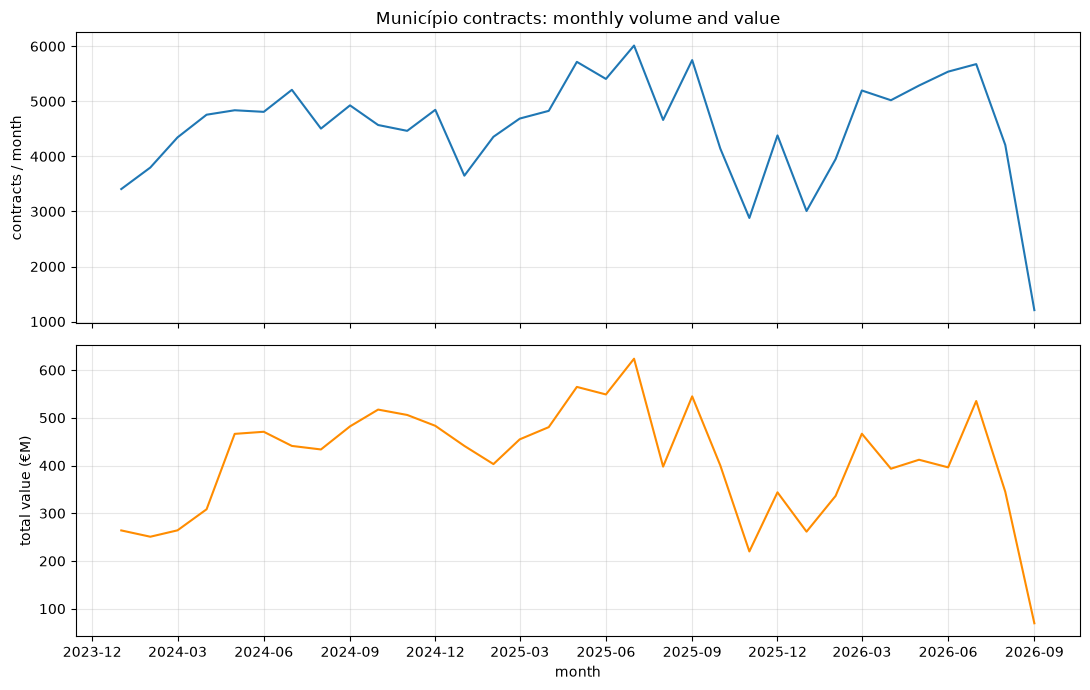

In [13]:
monthly = (
    municipio.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("month")
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Município contracts: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
municipio.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)


idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
10738425,"""Município de Cascais""",1.3180e8,"""Concurso público""",2024-05-15,"""Aquisição de serviços de trans…"
13482357,"""Município de Cascais""",5e7,"""Contratação excluída II""",2026-02-18,"""Promoção da construção, manute…"
13255178,"""Municipio de Vila Real de Sant…",4.4563e7,"""Concurso público""",2025-01-10,"""Empreitada de Reabilitação do …"
15277518,"""Município de Ovar""",3.9700e7,"""Concurso limitado por prévia q…",2026-07-07,"""Aquisição de serviços de recol…"
10761293,"""Município de Vila Nova de Gaia""",3.8355621e7,"""Concurso limitado por prévia q…",2024-06-06,"""Fornecimento de refeições em c…"
11603052,"""Município de Vila Nova de Fama…",3.6351e7,"""Concurso limitado por prévia q…",2025-07-17,"""Recolha e Transporte de Resídu…"
10927705,"""Município de Coimbra""",3.5689e7,"""Concurso público""",2024-06-25,"""Empreitada de """"1º Direito - P…"
10873361,"""Município de Sintra""",3.547152e7,"""Concurso público""",2024-08-13,"""Fornecimento e distribuição de…"
11638521,"""Municipio de Vila Real de Sant…",3.39e7,"""Concurso público""",2025-05-19,"""Prestação de Serviços para Rec…"


## Commentary and limitations

- The matching rule may include false positives (309 NIPCs vs 308 municipalities) and excludes `Câmara Municipal …`.
- `Ano` covers 2025–2026 only: no year-over-year comparison; the first and last months of the monthly series are partial.
- Top-value contracts should be checked as possible outliers or data-entry errors.- Municipalities are keyed by NIPC (`adjudicante_key`); a `-` NIPC would fall back to name similarity.

- Contracts with |value| below €10 are disregarded; `valor_por_dia` uses only 1–3650-day durations.